# Dinâmica da Criminalidade no Rio de Janeiro: Uma Análise Integrada Sobre Segurança Pública

*Análise Exploratória de Dados e Visualização*  
*FGV EMAp - Escola de Matemática Aplicada | Semestre 2026.2*

*Professor:* João Rulff  
 
*Autores:*   
Josué Santos de Oliveira da Silva   
Leonardo Cardia Bicca   
Luigi Parmeggiani Porto

Repositório do projeto: https://github.com/Josue-santoss/AEDV-A2-.git

## Introdução:

&emsp;O estado do Rio de Janeiro vivencia, há décadas, um dos cenários de segurança pública mais desafiadores e militarizados da América Latina. O presente artigo investiga a arquitetura espaço-temporal da violência letal fluminense a partir do cruzamento de 14 bases de microdados abertos fornecidas pelo Instituto de Segurança Pública (ISP-RJ), cobrindo o período longitudinal de 2003 a 2024. Estruturado em torno de sete perguntas de domínio articuladas lógica e metodologicamente, o estudo aborda desde a substituição tecnológica nos arsenais do crime organizado até as dinâmicas territoriais de letalidade policial e violência de gênero.  

## O Que o Leitor deve Saber:

1. Sobre os dados: Os dados têm origem no Instituto de Segurança Pública do Estado do Rio de Janeiro (ISP-RJ) e estão
estruturados em um conjunto de bases de dados abertas de frequências mensal e anual. A coleta e agregação
originais são feitas através dos registros de ocorrência das delegacias do estado.
Utilizaremos diversas tabelas relacionais que cobrem diferentes dimensões da segurança. As variáveis
mais relevantes para a análise incluem os recortes temporais e geográficos, tipificações de armas apreendidas
(com destaque para fuzis) e contagens e taxas (por 100 mil habitantes) de crimes contra a vida. Utilizaremos
também a tabela de relação CISP-AISP-RISP para realizar cruzamentos de dados espaciais entre os níveis
de delegacia, município e estado.


2. Siglas:  
- CISP: A Circunscrição Integrada de Segurança Pública é a área territorial que coincide com a jurisdição de uma delegacia distrital da Polícia Civil (SEPOL) e a subárea correspondente de uma companhia da Polícia Militar (SEPM).  
- AISP: A Área Integrada de Segurança Pública é uma divisão territorial que alinha a atuação da Polícia Militar (PMERJ) e da Polícia Civil (PCERJ) na mesma região para combater a criminalidade de forma conjunta.  
- RISP: A Região Integrada de Segurança Pública une os comandos intermediários das polícias, ou seja, os Departamentos de Polícia de Área (DPA) da Polícia Civil e os Comandos de Policiamento de Área (CPA) da Polícia Militar.

# Preparação das bases de dados

Esta parte do notebook constitui a **camada comum de dados** do projeto. Ela é executada antes das perguntas de pesquisa. Cada tabela derivada tem uma granularidade definida (por exemplo, uma linha por `ano` e `id_aisp`) e pode ser reutilizada por novas análises.

**Princípios:** preservar as bases originais em `dataframes_brutos`, manter as versões tratadas em `dataframes`, separar limpeza de relacionamento, construir indicadores uma única vez e registrar lacunas de cobertura sem inventar observações.

## 1. Bibliotecas e configuração

A URL abaixo é a mesma utilizada no carregamento do notebook original. Caso o repositório seja transferido, basta alterar `REPOSITORIO_DADOS`. O link de apresentação do projeto deve ser revisado separadamente se for diferente.

In [2]:
from io import BytesIO
from zipfile import ZipFile

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.io as pio
import plotly.express as px
import tempfile
import os
import sys
import requests
from matplotlib.patches import Patch

REPOSITORIO_DADOS = "josue-fgv/AEDV-A2-"
BRANCH_DADOS = "main"
PASTA_DADOS_ZIP = "/Projeto/Datas/"
PREFIXO_CSV = "br_rj_isp_estatisticas_seguranca_"
FATOR_TAXA = 100_000

URL_ZIP_DADOS = (
    f"https://github.com/{REPOSITORIO_DADOS}/archive/refs/heads/{BRANCH_DADOS}.zip"
)

## 2. Carregamento e catálogo das bases

Os arquivos CSV são identificados automaticamente a partir da pasta de dados. Novas bases adicionadas com a extensão `.csv` passam a integrar `dataframes` sem alterações no carregador.

In [3]:
def carregar_csvs_do_repositorio(url_zip: str, pasta_dados: str, prefixo: str) -> dict[str, pd.DataFrame]:
    """Lê os CSVs do ZIP do GitHub; mantém cada tabela separada e identificada pelo nome."""
    resposta_zip = requests.get(url_zip, timeout=60)
    resposta_zip.raise_for_status()

    bases_carregadas = {}
    with ZipFile(BytesIO(resposta_zip.content)) as arquivo_zip:
        for caminho in arquivo_zip.namelist():
            if pasta_dados not in caminho or not caminho.lower().endswith(".csv"):
                continue

            nome_arquivo = caminho.rsplit("/", 1)[-1]
            nome_base = nome_arquivo.removesuffix(".csv").removeprefix(prefixo)
            if nome_base in bases_carregadas:
                raise ValueError(f"Nome de base duplicado no ZIP: {nome_base}")

            with arquivo_zip.open(caminho) as conteudo_csv:
                bases_carregadas[nome_base] = pd.read_csv(
                    conteudo_csv, sep=None, engine="python"
                )

    if not bases_carregadas:
        raise ValueError(f"Nenhum arquivo CSV encontrado em {pasta_dados!r}.")
    return bases_carregadas


dataframes_brutos = carregar_csvs_do_repositorio(URL_ZIP_DADOS, PASTA_DADOS_ZIP, PREFIXO_CSV)
print(f"{len(dataframes_brutos)} bases importadas:", ", ".join(sorted(dataframes_brutos)))

15 bases importadas: PopulacaoEvolucaoMensalCisp, armas_apreendidas_mensal, armas_fogo_apreendidas_mensal, evolucao_mensal_cisp, evolucao_mensal_municipio, evolucao_mensal_uf, evolucao_mensal_upp, evolucao_policial_morto_servico_mensal, feminicidio_mensal_cisp, relacao_cisp_aisp_risp, taxa_evolucao_anual_municipio, taxa_evolucao_anual_uf, taxa_evolucao_mensal_municipio, taxa_evolucao_mensal_uf, taxa_letalidade


## 3. Limpeza e padronização

Esta rotina produz **cópias** das bases de entrada. `dataframes_brutos` preserva os CSVs importados; `dataframes` contém as bases tratadas. Corrige textos, preserva valores ausentes de chaves/população e define uma coluna temporal `data` nas tabelas mensais.

**Critério mantido do código original:** ausências em colunas numéricas de contagem iniciadas por `quantidade_` são preenchidas com zero. Essa hipótese deve ser confrontada com o dicionário oficial dos dados; não deve ser automaticamente aplicada às novas métricas.

In [4]:
CORRECOES_REGIAO = {
    "Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i": "Grande Niterói",
    "Grande Niteroi": "Grande Niterói",
}


def exigir_colunas(base: pd.DataFrame, colunas: list[str], nome_base: str) -> None:
    """Interrompe o processamento caso falte alguma coluna esperada."""
    faltantes = set(colunas).difference(base.columns)
    if faltantes:
        raise KeyError(f"{nome_base}: colunas ausentes: {sorted(faltantes)}")


def limpar_bases_isp(bases: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:
    """Padroniza as bases sem alterar os DataFrames de entrada."""
    bases_tratadas = {}

    for nome_base, base_original in bases.items():
        base = base_original.copy()
        base.columns = base.columns.str.strip()

        # Limpeza de textos sem transformar ausências (NaN) em strings 'nan'.
        for coluna in base.select_dtypes(include=["object", "string"]).columns:
            base[coluna] = base[coluna].map(
                lambda valor: valor.strip() if isinstance(valor, str) else valor
            )

        if "regiao" in base.columns:
            base["regiao"] = base["regiao"].replace(CORRECOES_REGIAO)

        # Hipótese de imputação do projeto: somente contagens de ocorrências.
        for coluna in base.select_dtypes(include="number").columns:
            if coluna.startswith("quantidade_"):
                base[coluna] = base[coluna].fillna(0)

        if "ano" in base.columns:
            base["ano"] = pd.to_numeric(base["ano"], errors="raise").astype("int64")
        if "mes" in base.columns:
            base["mes"] = pd.to_numeric(base["mes"], errors="raise").astype("int64")
        if {"ano", "mes"}.issubset(base.columns):
            base["data"] = pd.to_datetime(
                {"year": base["ano"], "month": base["mes"], "day": 1},
                errors="raise"
            )

        bases_tratadas[nome_base] = base

    return bases_tratadas


dataframes = limpar_bases_isp(dataframes_brutos)
print("Bases padronizadas:", len(dataframes))

Bases padronizadas: 15


## 4. Referências às bases de trabalho

Os apelidos abaixo conservam os nomes esperados pelas células das perguntas. **As bases continuam disponíveis em `dataframes`**; os apelidos não representam novas cópias.

In [5]:
(
    df_armas,
    df_armas_fogo,
    df_cisp_mensal,
    df_mun_mensal,
    df_evol_uf,
    df_evol_upp,
    df_policial,
    df_fem_cisp,
    df_rel,
    df_taxa_anual_municipio,
    df_taxa_anual_uf,
    df_taxa_mun_mensal,
    df_taxa_mensal_uf,
    df_letalidade,
    df_populacao_mensal_cisp,
) = (
    dataframes["armas_apreendidas_mensal"],
    dataframes["armas_fogo_apreendidas_mensal"],
    dataframes["evolucao_mensal_cisp"],
    dataframes["evolucao_mensal_municipio"],
    dataframes["evolucao_mensal_uf"],
    dataframes["evolucao_mensal_upp"],
    dataframes["evolucao_policial_morto_servico_mensal"],
    dataframes["feminicidio_mensal_cisp"],
    dataframes["relacao_cisp_aisp_risp"],
    dataframes["taxa_evolucao_anual_municipio"],
    dataframes["taxa_evolucao_anual_uf"],
    dataframes["taxa_evolucao_mensal_municipio"],
    dataframes["taxa_evolucao_mensal_uf"],
    dataframes["taxa_letalidade"],
    dataframes["PopulacaoEvolucaoMensalCisp"],
)

# Tabela de inventário: facilita identificar novas fontes e colunas disponíveis.
inventario_bases = pd.DataFrame([
    {"base": nome_base, "linhas": len(base), "colunas": len(base.columns)}
    for nome_base, base in sorted(dataframes.items())
])
inventario_bases

,base,linhas,colunas
0,PopulacaoEvolucaoMensalCisp,31534,5
1,armas_apreendidas_mensal,32476,43
2,armas_fogo_apreendidas_mensal,6206,8
3,evolucao_mensal_cisp,37999,62
4,evolucao_mensal_municipio,13984,59
5,evolucao_mensal_uf,428,57
6,evolucao_mensal_upp,7980,39
7,evolucao_policial_morto_servico_mensal,38273,6
8,feminicidio_mensal_cisp,16724,10
9,relacao_cisp_aisp_risp,147,6


# Relacionamentos e dimensões territoriais

As relações territoriais são construídas **antes** de qualquer cálculo de taxas. Uma chave de relacionamento não deve ser substituída por uma descrição textual. As descrições ficam em tabelas de dimensão.

## 5. Relações entre CISP, AISP e regiões

`df_rel` é a referência da correspondência CISP–AISP–RISP. O agrupamento por região pode conter uma AISP em mais de uma categoria; portanto, a relação `regiao → AISP` não é pressuposta como exclusiva.

In [6]:
exigir_colunas(df_rel, ["id_cisp", "id_aisp", "regiao"], "df_rel")

# Estrutura consultável pelo nome da região (sem depender da ordem do groupby).
grupos = df_rel.groupby("regiao")["id_aisp"].unique()
aisps_por_regiao = {
    regiao: sorted(int(aisp) for aisp in identificadores if pd.notna(aisp))
    for regiao, identificadores in grupos.items()
}

print("Regiões disponíveis:", ", ".join(aisps_por_regiao))

Regiões disponíveis: Baixadas Litorâneas, Centro-Sul Fluminense, Costa Verde, Metropolitana, Médio Paraíba, Noroeste Fluminense, Norte Fluminense, Serrana


## 6. Padronização da população mensal por CISP

**Granularidade:** `(ano, mes, id_cisp)`.

Conserva-se a metodologia do notebook original: converter a população mensal para inteiro, truncando a parte decimal, **antes** do cálculo da média anual. Não se soma a população dos meses.

In [7]:
# Trabalhar em cópia para não alterar a tabela importada em dataframes.
df_populacao_mensal_cisp = df_populacao_mensal_cisp.rename(
    columns={"circ": "id_cisp", "pop_circ": "populacao"}
).copy()
exigir_colunas(
    df_populacao_mensal_cisp,
    ["ano", "mes", "id_cisp", "populacao"],
    "df_populacao_mensal_cisp",
)

populacao_texto = (
    df_populacao_mensal_cisp["populacao"]
    .astype("string")
    .str.replace(",", ".", regex=False)
)
populacao_numerica = pd.to_numeric(populacao_texto, errors="raise")
if populacao_numerica.isna().any() or (populacao_numerica < 0).any():
    raise ValueError("Há populações ausentes ou negativas na base mensal por CISP.")

df_populacao_mensal_cisp["populacao"] = populacao_numerica.astype("int64")

duplicatas_mensais = df_populacao_mensal_cisp.duplicated(
    subset=["ano", "mes", "id_cisp"], keep=False
)
if duplicatas_mensais.any():
    raise ValueError("Há registros duplicados de (ano, mes, id_cisp) na população mensal.")

## 7. População anual por CISP

**Granularidade:** `(ano, id_cisp)`. A estimativa anual é a média dos valores mensais disponíveis, como no cálculo original. Para futuras análises, a base mensal permanece acessível separadamente.

In [8]:
df_populacao_anual_cisp = (
    df_populacao_mensal_cisp
    .groupby(["ano", "id_cisp"], as_index=False)["populacao"]
    .mean()
)
df_populacao_anual_cisp.head()

,ano,id_cisp,populacao
0,2003,1,1550.500000
1,2003,4,29894.000000
2,2003,5,35780.916667
3,2003,6,76537.083333
4,2003,7,38793.583333


## 8. Dimensão de relacionamento CISP → AISP

Atribui-se uma AISP por CISP, como no notebook original. Diferentemente de `.first()` sem verificação, a tabela de correspondência explicita chaves e sinaliza conflitos. **Uma eventual mudança histórica de jurisdição exige uma tabela CISP–AISP com vigência temporal; o arquivo atual não é tratado como histórico.**

In [9]:
df_mapa_cisp_aisp = (
    df_rel[["id_cisp", "id_aisp"]]
    .dropna(subset=["id_cisp", "id_aisp"])
    .drop_duplicates()
    .copy()
)

conflitos_cisp_aisp = (
    df_mapa_cisp_aisp
    .groupby("id_cisp")["id_aisp"]
    .nunique()
    .loc[lambda serie: serie > 1]
)
if not conflitos_cisp_aisp.empty:
    raise ValueError(
        "Uma CISP foi associada a mais de uma AISP. "
        "Não é seguro escolher .first(); verifique a correspondência temporal. "
        f"Exemplos: {conflitos_cisp_aisp.head().to_dict()}"
    )

# Mantido como recurso de consulta, sem ser a fonte primária da relação.
aisp_de_cisp = df_mapa_cisp_aisp.set_index("id_cisp")["id_aisp"].to_dict()

## 9. População anual por AISP

**Granularidade:** `(ano, id_aisp)`. Primeiro associamos a CISP à AISP (`many_to_one`); depois, somamos as estimativas anuais das CISPs pertencentes a cada AISP. CISPs sem correspondência são registradas em `populacao_cisp_sem_aisp`, em vez de serem ignoradas sem rastreabilidade.

In [10]:
populacao_cisp_com_aisp = df_populacao_anual_cisp.merge(
    df_mapa_cisp_aisp,
    on="id_cisp",
    how="left",
    validate="many_to_one",
    indicator="situacao_mapeamento",
)

populacao_cisp_sem_aisp = populacao_cisp_com_aisp.loc[
    populacao_cisp_com_aisp["id_aisp"].isna(),
    ["ano", "id_cisp", "populacao"],
].copy()

populacao_por_ano_aisp = (
    populacao_cisp_com_aisp
    .dropna(subset=["id_aisp"])
    .groupby(["ano", "id_aisp"], as_index=False)["populacao"]
    .sum(min_count=1)
)

print("CISPs/anos sem AISP associada:", len(populacao_cisp_sem_aisp))
populacao_por_ano_aisp.head()

CISPs/anos sem AISP associada: 6


,ano,id_aisp,populacao
0,2003,2.0,227239.333333
1,2003,3.0,525360.583333
2,2003,4.0,152657.083333
3,2003,5.0,106019.000000
4,2003,6.0,351785.000000


## 10. Dimensão de nomes das AISPs

Nomes de apresentação devem ter **uma fonte e uma definição únicas**. `dim_aisp` pode receber posteriormente colunas de localização, categorias e metadados; os indicadores continuam vinculados por `id_aisp`.

Referência declarada no notebook original: [Relação RISP × AISP × CISP — ISP-RJ](https://www.ispdados.rj.gov.br/Arquivos/Relacao_RISPxAISPxCISP.pdf). A nomenclatura abaixo foi preservada do trabalho, **sem validação histórica de vigência**.

In [11]:
nomes_aisp = {
    1: "São Gonçalo",
    2: "Botafogo / Flamengo",
    3: "Méier / Cachambi",
    4: "São Cristóvão / Estácio",
    5: "Centro / Santa Teresa",
    6: "Tijuca / Maracanã",
    7: "São Gonçalo",
    8: "Campos dos Goytacazes",
    9: "Madureira / Cascadura",
    10: "Barra do Piraí / Valença",
    11: "Nova Friburgo",
    12: "Niterói / Maricá",
    14: "Bangu / Realengo",
    15: "Duque de Caxias",
    16: "Penha / Olaria",
    17: "Ilha do Governador",
    18: "Jacarepaguá",
    19: "Copacabana / Leme",
    20: "Nova Iguaçu / Mesquita",
    21: "São João de Meriti",
    22: "Maré / Bonsucesso",
    23: "Ipanema / Leblon / Rocinha",
    24: "Itaguaí / Seropédica",
    25: "Região dos Lagos",
    26: "Petrópolis",
    27: "Santa Cruz / Guaratiba",
    28: "Volta Redonda / Barra Mansa",
    29: "Itaperuna",
    30: "Teresópolis",
    31: "Barra da Tijuca / Recreio",
    32: "Macaé / Rio das Ostras",
    33: "Angra dos Reis / Mangaratiba",
    34: "Magé / Guapimirim",
    35: "Itaboraí / Rio Bonito",
    36: "Santo Antônio de Pádua",
    37: "Resende / Itatiaia",
    38: "Três Rios / Paraíba do Sul",
    39: "Belford Roxo",
    40: "Campo Grande",
    41: "Irajá / Pavuna",
    43: "Paraty",
}

# Tabela de dimensão para cruzamentos presentes e futuros.
dim_aisp = pd.DataFrame(
    [(codigo, descricao) for codigo, descricao in nomes_aisp.items()],
    columns=["id_aisp", "nome_aisp"],
)
if dim_aisp["id_aisp"].duplicated().any():
    raise ValueError("Há identificadores de AISP repetidos na dimensão.")

populacao_por_ano_aisp = populacao_por_ano_aisp.merge(
    dim_aisp,
    on="id_aisp",
    how="left",
    validate="many_to_one",
)
populacao_por_ano_aisp.head()

,ano,id_aisp,populacao,nome_aisp
0,2003,2.0,227239.333333,Botafogo / Flamengo
1,2003,3.0,525360.583333,Méier / Cachambi
2,2003,4.0,152657.083333,São Cristóvão / Estácio
3,2003,5.0,106019.000000,Centro / Santa Teresa
4,2003,6.0,351785.000000,Tijuca / Maracanã


# Construção de indicadores gerais

Estas tabelas são **insumos reutilizáveis**, não respostas a uma pergunta específica. Novos indicadores devem nascer a partir das mesmas chaves e das mesmas bases de referência, sem recalcular ou modificar as tabelas originais.

## 11. Contagens anuais de letalidade violenta por AISP

**Granularidade:** `(ano, id_aisp)`. Mantém-se a soma das contagens mensais. A função aceita outras colunas de contagem quando precisarmos ampliar os indicadores de segurança pública.

In [12]:
def agregar_contagens_aisp_ano(
    base: pd.DataFrame,
    colunas_contagem: list[str],
) -> pd.DataFrame:
    """Agrupa contagens aditivas por ano e AISP."""
    exigir_colunas(base, ["ano", "id_aisp", *colunas_contagem], "base de ocorrências")
    return (
        base.groupby(["ano", "id_aisp"], as_index=False)[colunas_contagem]
        .sum()
    )


mortes_aisp_ano = agregar_contagens_aisp_ano(
    df_cisp_mensal,
    ["quantidade_letalidade_violenta"],
)

# Total anual estadual, sem período fixo: cada pergunta aplica seu recorte temporal.
letalidade_anual = (
    mortes_aisp_ano
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
    .sort_values("ano")
)
mortes_aisp_ano.head()

,ano,id_aisp,quantidade_letalidade_violenta
0,2003,1,156
1,2003,2,24
2,2003,3,345
3,2003,4,45
4,2003,5,44


## 12. Painel AISP–ano e taxas por 100 mil habitantes

**Granularidade:** `(ano, id_aisp)`. `estatisticas_aisp` reúne contagem, população, nome e taxa; `validate='one_to_one'` verifica se os dois lados possuem chaves únicas. Não se calculam taxas para populações nulas ou não positivas: tais casos permanecem como `NaN` e são documentados no diagnóstico.

A série populacional fornecida cobre menos anos do que as ocorrências. O painel de taxas é restringido aos anos disponíveis na população; as contagens originais permanecem completas.

In [13]:
def taxa_por_100_mil(
    quantidade: pd.Series,
    populacao: pd.Series,
    fator: int = FATOR_TAXA,
) -> pd.Series:
    """Taxa por habitante, com NaN quando falta denominador válido."""
    denominador_valido = populacao.where(populacao > 0)
    return quantidade.div(denominador_valido).mul(fator)


anos_com_populacao = populacao_por_ano_aisp["ano"].unique()

estatisticas_aisp = (
    mortes_aisp_ano.loc[mortes_aisp_ano["ano"].isin(anos_com_populacao)]
    .merge(
        populacao_por_ano_aisp,
        on=["ano", "id_aisp"],
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

estatisticas_aisp["taxa_letalidade"] = taxa_por_100_mil(
    estatisticas_aisp["quantidade_letalidade_violenta"],
    estatisticas_aisp["populacao"],
)
estatisticas_aisp.head()

,ano,id_aisp,quantidade_letalidade_violenta,populacao,nome_aisp,_merge,taxa_letalidade
0,2003,1,156,NaN,NaN,left_only,NaN
1,2003,2,24,227239.333333,Botafogo / Flamengo,both,10.561552
2,2003,3,345,525360.583333,Méier / Cachambi,both,65.669182
3,2003,4,45,152657.083333,São Cristóvão / Estácio,both,29.477833
4,2003,5,44,106019.000000,Centro / Santa Teresa,both,41.501995


## 13. Verificações da cobertura do painel

As AISPs sem população não devem receber taxas artificiais. Este diagnóstico pode ser estendido a novos cruzamentos e serve de referência para avaliar a cobertura das séries.

In [14]:
diagnostico_integracao_aisp = (
    estatisticas_aisp["_merge"]
    .value_counts()
    .rename_axis("situacao")
    .reset_index(name="quantidade_linhas")
)

linhas_sem_taxa_letalidade = estatisticas_aisp.loc[
    estatisticas_aisp["taxa_letalidade"].isna(),
    ["ano", "id_aisp", "nome_aisp", "quantidade_letalidade_violenta", "populacao"],
].copy()

print("Cobertura do relacionamento mortes × população:")
print(diagnostico_integracao_aisp.to_string(index=False))
print("Linhas sem taxa de letalidade:", len(linhas_sem_taxa_letalidade))
print("CISPs/anos sem relacionamento territorial:", len(populacao_cisp_sem_aisp))
aisps_sem_nome = sorted(
    set(mortes_aisp_ano["id_aisp"].dropna().astype(int))
    - set(dim_aisp["id_aisp"])
)
if aisps_sem_nome:
    print("Identificadores de AISP sem nome na dimensão:", aisps_sem_nome)
if not linhas_sem_taxa_letalidade.empty:
    display(linhas_sem_taxa_letalidade.head(10))

Cobertura do relacionamento mortes × população:
  situacao  quantidade_linhas
      both                770
 left_only                 18
right_only                  0
Linhas sem taxa de letalidade: 18
CISPs/anos sem relacionamento territorial: 6
Identificadores de AISP sem nome na dimensão: [13]


,ano,id_aisp,nome_aisp,quantidade_letalidade_violenta,populacao
0,2003,1,NaN,156,NaN
12,2003,13,NaN,13,NaN
39,2004,1,NaN,175,NaN
51,2004,13,NaN,18,NaN
78,2005,1,NaN,133,NaN
90,2005,13,NaN,17,NaN
118,2006,1,NaN,101,NaN
130,2006,13,NaN,14,NaN
158,2007,1,NaN,108,NaN
170,2007,13,NaN,20,NaN


# Estatísticas descritivas reutilizáveis

Este bloco sintetiza a **distribuição entre AISPs**, e não a taxa do estado. A média simples de taxas por AISP dá o mesmo peso a cada AISP; a taxa estadual exigiria somar os eventos e as populações antes da divisão.

## 14. Resumo anual das taxas por AISP

O cálculo do desvio-padrão mantém `ddof=0`. Para ampliar o projeto, a função pode receber outra coluna de taxa e retornar o mesmo conjunto de estatísticas por ano.

In [15]:
def resumir_taxas_por_ano(
    painel: pd.DataFrame,
    coluna_taxa: str = "taxa_letalidade",
) -> pd.DataFrame:
    """Resume a distribuição anual de uma taxa entre AISPs."""
    exigir_colunas(painel, ["ano", coluna_taxa], "painel de taxas")
    resumo = (
        painel.groupby("ano")[coluna_taxa]
        .agg(
            media="mean",
            mediana="median",
            minimo="min",
            maximo="max",
            q1=lambda serie: serie.quantile(0.25),
            q3=lambda serie: serie.quantile(0.75),
            desvio_padrao=lambda serie: serie.std(ddof=0),
        )
        .reset_index()
    )
    resumo["variancia"] = resumo["desvio_padrao"] ** 2
    resumo["amplitude_interquartil"] = resumo["q3"] - resumo["q1"]
    resumo["coef_variacao"] = (
        resumo["desvio_padrao"]
        .div(resumo["media"].where(resumo["media"] != 0))
        .mul(100)
    )
    return resumo


resumo_estatistico = resumir_taxas_por_ano(estatisticas_aisp)
resumo_estatistico.head()

,ano,media,mediana,minimo,maximo,q1,q3,desvio_padrao,variancia,amplitude_interquartil,coef_variacao
0,2003,50.152753,41.501995,7.563091,302.156643,27.861555,54.822650,48.323071,2335.119221,26.961095,96.351781
1,2004,47.841119,44.389547,9.992640,243.567033,20.495192,58.776410,41.080699,1687.623833,38.281218,85.869019
2,2005,48.247022,43.233761,10.990904,208.015163,24.698785,62.595296,33.984999,1154.980125,37.896511,70.439578
3,2006,45.728709,44.385764,8.339789,197.399203,24.081242,55.712753,31.752893,1008.246201,31.631511,69.437544
4,2007,45.894702,44.249527,11.395865,212.952836,22.910260,56.893767,34.172915,1167.788100,33.983507,74.459389


## 15. Contrato de dados para as próximas análises

| Objeto | Uma linha por | Uso previsto |
|:--|:--|:--|
| `dataframes_brutos` | depende da fonte | CSVs originais para auditoria e reprocessamento |
| `dataframes` | depende da fonte | dados tratados para diferentes perguntas |
| `df_rel` | conforme arquivo ISP | relações territoriais de origem |
| `df_mapa_cisp_aisp` | CISP | correspondência territorial sem ambiguidades |
| `dim_aisp` | AISP | atributos descritivos expansíveis |
| `df_populacao_mensal_cisp` | ano, mês e CISP | série populacional de origem |
| `df_populacao_anual_cisp` | ano e CISP | média das populações mensais |
| `populacao_por_ano_aisp` | ano e AISP | denominador anual para indicadores |
| `mortes_aisp_ano` | ano e AISP | contagem anual de letalidade violenta |
| `estatisticas_aisp` | ano e AISP | painel de métricas integradas |
| `resumo_estatistico` | ano | distribuição de taxas entre AISPs |

**Para novas métricas:** acrescentar a agregação correspondente, integrar pelo mesmo par de chaves e calcular a nova taxa com `taxa_por_100_mil`. **Para novos relacionamentos:** criar uma dimensão/correspondência validada, sem reutilizar variáveis para diferentes sentidos. Mudanças históricas dos limites de AISP/CISP requerem uma tabela temporal validada antes de comparar territórios ao longo do tempo.

# Perguntas:

## Pergunta 1 - Qual é a evolução histórica do volume absoluto e da taxa (por 100 mil habitantes) de armas de fogo e fuzis apreendidos no estado do Rio de Janeiro nos últimos anos?


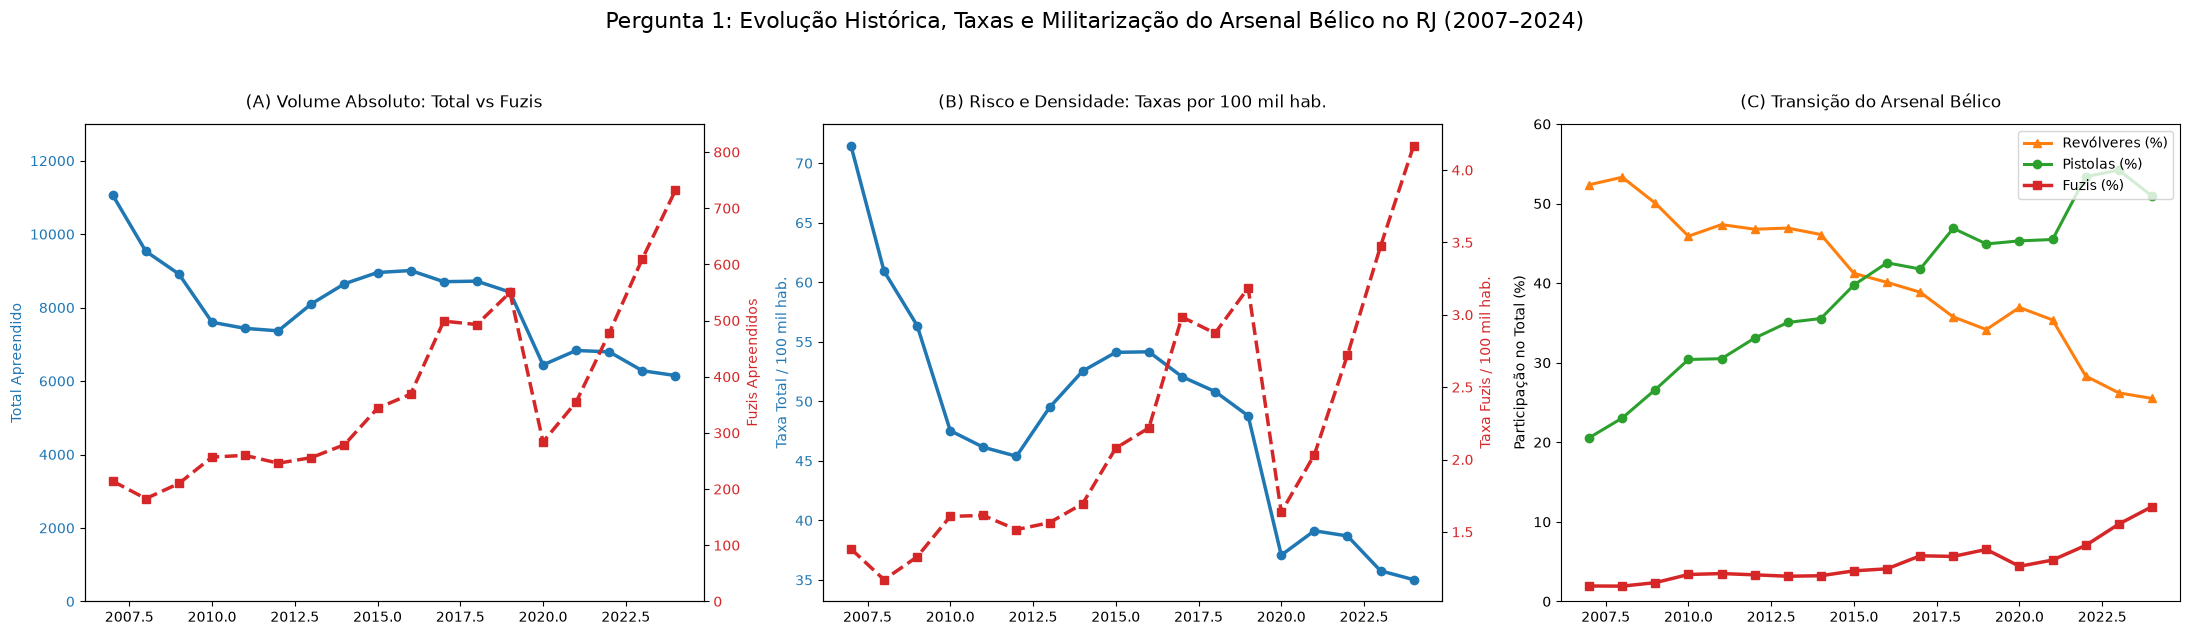

In [16]:
#######################################################################
#Limpeza dos dados
df_cisp_mensal['regiao'] = df_cisp_mensal['regiao'].replace({
    'Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i': 'Grande Niterói',
    'Grande Niteroi': 'Grande Niterói'
})
df_letalidade['regiao'] = df_letalidade['regiao'].replace({'Grande Niteroi': 'Grande Niterói'})
pop_uf = df_letalidade[df_letalidade['regiao'] == 'Estado'][['ano', 'populacao']].drop_duplicates().set_index('ano')['populacao']
########################################################################
armas_anual = df_armas[df_armas['ano'].between(2007, 2024)].groupby('ano')[['quantidade_arma_fogo_total', 'quantidade_fuzil', 'quantidade_pistola', 'quantidade_revolver']].sum()
armas_anual['populacao'] = pop_uf
armas_anual['populacao'] = armas_anual['populacao'].ffill()

armas_anual['taxa_armas_100k'] = (armas_anual['quantidade_arma_fogo_total'] / armas_anual['populacao']) * 100000
armas_anual['taxa_fuzil_100k'] = (armas_anual['quantidade_fuzil'] / armas_anual['populacao']) * 100000
armas_anual['prop_fuzil_pct'] = (armas_anual['quantidade_fuzil'] / armas_anual['quantidade_arma_fogo_total']) * 100
armas_anual['prop_pistola_pct'] = (armas_anual['quantidade_pistola'] / armas_anual['quantidade_arma_fogo_total']) * 100
armas_anual['prop_revolver_pct'] = (armas_anual['quantidade_revolver'] / armas_anual['quantidade_arma_fogo_total']) * 100

#print("Resumo Decenal da Evolução de Armas e Fuzis (Amostra Bienal):")
#display_cols = ['quantidade_arma_fogo_total', 'taxa_armas_100k', 'quantidade_fuzil', 'taxa_fuzil_100k', 'prop_revolver_pct', 'prop_pistola_pct', 'prop_fuzil_pct']
#print(armas_anual.loc[[2007, 2011, 2015, 2019, 2024], display_cols].round(2))

# Expansão para 3 painéis (1x3)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))

color1, color2 = '#1f77b4', '#d62728'

# Painel 1 (ax1): Volumes Absolutos (Seu código original)
ax1.plot(armas_anual.index, armas_anual['quantidade_arma_fogo_total'], marker='o', color=color1, linewidth=2.5, label='Total Armas')
ax1.set_xlabel('')
ax1.set_ylabel('Total Apreendido', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 13000)

ax1_twin = ax1.twinx()
ax1_twin.plot(armas_anual.index, armas_anual['quantidade_fuzil'], marker='s', color=color2, linewidth=2.5, linestyle='--')
ax1_twin.set_ylabel('Fuzis Apreendidos', color=color2)
ax1_twin.tick_params(axis='y', labelcolor=color2)
ax1_twin.set_ylim(0, 850)
ax1.set_title('(A) Volume Absoluto: Total vs Fuzis', pad=12)

# Painel 2 (ax2): Taxa por 100 mil habitantes (Nova inserção)
ax2.plot(armas_anual.index, armas_anual['taxa_armas_100k'], marker='o', color=color1, linewidth=2.5)
ax2.set_xlabel('')
ax2.set_ylabel('Taxa Total / 100 mil hab.', color=color1)
ax2.tick_params(axis='y', labelcolor=color1)

ax2_twin = ax2.twinx()
ax2_twin.plot(armas_anual.index, armas_anual['taxa_fuzil_100k'], marker='s', color=color2, linewidth=2.5, linestyle='--')
ax2_twin.set_ylabel('Taxa Fuzis / 100 mil hab.', color=color2)
ax2_twin.tick_params(axis='y', labelcolor=color2)
ax2.set_title('(B) Risco e Densidade: Taxas por 100 mil hab.', pad=12)

# Painel 3 (ax3): Proporções (Seu ax2 original)
anos = armas_anual.index
ax3.plot(anos, armas_anual['prop_revolver_pct'], marker='^', color='#ff7f0e', linewidth=2.2, label='Revólveres (%)')
ax3.plot(anos, armas_anual['prop_pistola_pct'], marker='o', color='#2ca02c', linewidth=2.2, label='Pistolas (%)')
ax3.plot(anos, armas_anual['prop_fuzil_pct'], marker='s', color='#d62728', linewidth=2.5, label='Fuzis (%)')
ax3.set_xlabel('')
ax3.set_ylabel('Participação no Total (%)')
ax3.set_ylim(0, 60)
ax3.set_title('(C) Transição do Arsenal Bélico', pad=12)
ax3.legend(frameon=True, facecolor='white', loc='upper right')

plt.suptitle('Pergunta 1: Evolução Histórica, Taxas e Militarização do Arsenal Bélico no RJ (2007–2024)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()


## Pergunta 2 - Quais Áreas Integradas (AISP) concentram as maiores taxas proporcionais de letalidade violenta e feminicıdio ao longo do tempo?

### Mapa da letalidade violenta por ano



In [17]:
def baixar_shapefile_github(url: str) -> gpd.GeoDataFrame:
    """Baixa o zip do GitHub, salva num arquivo temporário e lê no GeoPandas."""
    resposta = requests.get(url, timeout=60)
    resposta.raise_for_status() 
    
    with tempfile.NamedTemporaryFile(delete=False, suffix='.zip') as tmp:
        tmp.write(resposta.content)
        tmp_path = tmp.name
        
    try:
        gdf = gpd.read_file(f"zip://{tmp_path}")
    finally:
        os.unlink(tmp_path)
        
    return gdf

def carregar_e_preparar_dados(dataframes: dict) -> dict:
    """Consolida as bases tabulares em memória e lê os shapefiles diretamente do GitHub."""
    # 1. Bases tabulares
    df_armas = dataframes["armas_apreendidas_mensal"]
    df_cisp_mensal = dataframes["evolucao_mensal_cisp"]
    df_mun_mensal = dataframes["evolucao_mensal_municipio"]
    df_taxa_mun_mensal = dataframes["taxa_evolucao_mensal_municipio"]
    df_fem_cisp = dataframes["feminicidio_mensal_cisp"]
    df_letalidade = dataframes["taxa_letalidade"]
    df_policial = dataframes["evolucao_policial_morto_servico_mensal"]
    df_rel = dataframes["relacao_cisp_aisp_risp"]
    
    # 2. Bases espaciais
    base_url = "https://raw.githubusercontent.com/josue-fgv/AEDV-A2-/main/Projeto/Datas"
    print("Baixando shapefiles de forma segura...")
    gdf_cisp = baixar_shapefile_github(f"{base_url}/CISP.zip")
    gdf_risp = baixar_shapefile_github(f"{base_url}/RISP.zip")
    gdf_aisp = baixar_shapefile_github(f"{base_url}/AISP.zip")
    print("Arquivos espaciais carregados com sucesso!")
    
    # 3. Tratamentos e Cruzamentos
    correcao_regiao = {
        "Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i": "Grande Niterói",
        "Grande Niteroi": "Grande Niterói"
    }
    df_cisp_mensal["regiao"] = df_cisp_mensal["regiao"].replace(correcao_regiao)
    df_mun_mensal["regiao"] = df_mun_mensal["regiao"].replace(correcao_regiao)
    df_letalidade["regiao"] = df_letalidade["regiao"].replace(correcao_regiao)

    aisp_names = {
        2: "AISP 02 (Botafogo/Catete)", 3: "AISP 03 (Méier/Jacarezinho)", 4: "AISP 04 (São Cristóvão/Centro)",
        5: "AISP 05 (Praça da Harmonia/Centro)", 6: "AISP 06 (Tijuca/Vila Isabel)", 7: "AISP 07 (São Gonçalo)",
        8: "AISP 08 (Campos dos Goytacazes)", 9: "AISP 09 (Rocha Miranda/Madureira)", 10: "AISP 10 (Barra do Piraí/Valença)",
        11: "AISP 11 (Nova Friburgo)", 12: "AISP 12 (Niterói/Maricá)", 14: "AISP 14 (Bangu/Senador Camará)",
        15: "AISP 15 (Duque de Caxias)", 16: "AISP 16 (Olaria/Penha/Alemão)", 17: "AISP 17 (Ilha do Governador)",
        18: "AISP 18 (Jacarepaguá/CDD)", 19: "AISP 19 (Copacabana)", 20: "AISP 20 (Nova Iguaçu/Mesquita)",
        21: "AISP 21 (São João de Meriti)", 22: "AISP 22 (Maré/Bonsucesso)", 23: "AISP 23 (Leblon/Rocinha)",
        24: "AISP 24 (Queimados/Japeri/Itaguaí)", 25: "AISP 25 (Cabo Frio/Região dos Lagos)", 26: "AISP 26 (Petrópolis)",
        27: "AISP 27 (Santa Cruz/Sepetiba)", 28: "AISP 28 (Volta Redonda/Barra Mansa)", 29: "AISP 29 (Itaperuna/Noroeste)",
        30: "AISP 30 (Teresópolis)", 31: "AISP 31 (Barra da Tijuca/Recreio)", 32: "AISP 32 (Macaé/Rio das Ostras)",
        33: "AISP 33 (Angra dos Reis/Costa Verde)", 34: "AISP 34 (Magé/Guapimirim)", 35: "AISP 35 (Itaboraí/Tanguá)",
        36: "AISP 36 (Santo Antônio de Pádua)", 37: "AISP 37 (Resende/Itatiaia)", 38: "AISP 38 (Três Rios/Paraíba do Sul)",
        39: "AISP 39 (Belford Roxo)", 40: "AISP 40 (Campo Grande)", 41: "AISP 41 (Irajá/Pavuna/Acari)"
    }
    aisp_coords = {
        2: (-43.182, -22.951), 3: (-43.278, -22.902), 4: (-43.218, -22.912), 5: (-43.180, -22.908),
        6: (-43.238, -22.923), 7: (-43.053, -22.826), 8: (-41.324, -21.754), 9: (-43.344, -22.856),
        10: (-43.829, -22.469), 11: (-42.531, -22.281), 12: (-43.103, -22.883), 14: (-43.466, -22.875),
        15: (-43.311, -22.785), 16: (-43.272, -22.842), 17: (-43.208, -22.805), 18: (-43.365, -22.938),
        19: (-43.185, -22.969), 20: (-43.451, -22.759), 21: (-43.372, -22.803), 22: (-43.245, -22.858),
        23: (-43.225, -22.981), 24: (-43.559, -22.716), 25: (-42.028, -22.880), 26: (-43.178, -22.505),
        27: (-43.678, -22.918), 28: (-44.104, -22.523), 29: (-41.889, -21.205), 30: (-42.966, -22.412),
        31: (-43.395, -23.001), 32: (-41.786, -22.371), 33: (-44.318, -23.006), 34: (-43.041, -22.652),
        35: (-42.859, -22.744), 36: (-42.132, -21.539), 37: (-44.447, -22.468), 38: (-43.209, -22.116),
        39: (-43.399, -22.764), 40: (-43.559, -22.902), 41: (-43.332, -22.825)
    }

    aisp_reg_map = df_cisp_mensal[df_cisp_mensal["ano"] >= 2018].groupby("id_aisp")["regiao"].agg(
        lambda x: x.mode()[0] if len(x.mode()) > 0 else "Interior"
    ).to_dict()
    aisp_reg_map[39] = "Baixada Fluminense"
    aisp_reg_map[35] = "Grande Niterói"
    
    # 1. Painel Anual por AISP (2007-2024)
    armas_aisp_yr = df_armas[df_armas["ano"].between(2007, 2024)].groupby(["ano", "id_aisp"])[
        ["quantidade_fuzil", "quantidade_pistola", "quantidade_revolver", "quantidade_arma_fogo_total"]
    ].sum().reset_index()

    crimes_aisp_yr = df_cisp_mensal[df_cisp_mensal["ano"].between(2007, 2024)].groupby(["ano", "id_aisp"])[
        ["quantidade_letalidade_violenta", "quantidade_homicidio_doloso", "quantidade_homicidio_intervencao_policial"]
    ].sum().reset_index()

    df_aisp_anual = pd.merge(armas_aisp_yr, crimes_aisp_yr, on=["ano", "id_aisp"], how="inner")
    df_aisp_anual = df_aisp_anual[df_aisp_anual["id_aisp"].isin(aisp_names.keys())].copy()
    df_aisp_anual["nome_aisp"] = df_aisp_anual["id_aisp"].map(aisp_names)
    df_aisp_anual["regiao"] = df_aisp_anual["id_aisp"].map(aisp_reg_map)
    df_aisp_anual["lon"] = df_aisp_anual["id_aisp"].map(lambda x: aisp_coords[x][0])
    df_aisp_anual["lat"] = df_aisp_anual["id_aisp"].map(lambda x: aisp_coords[x][1])
    df_aisp_anual["prop_intervencao_pct"] = np.where(
        df_aisp_anual["quantidade_letalidade_violenta"] > 0,
        (df_aisp_anual["quantidade_homicidio_intervencao_policial"] / df_aisp_anual["quantidade_letalidade_violenta"]) * 100,
        0.0
    ).round(1)

    # 2. Evolução Histórica do Arsenal Bélico (2007-2024)
    armas_uf = df_armas[df_armas["ano"].between(2007, 2024)].groupby("ano")[
        ["quantidade_arma_fogo_total", "quantidade_fuzil", "quantidade_pistola", "quantidade_revolver"]
    ].sum().reset_index()
    armas_uf["Revólveres (%)"] = ((armas_uf["quantidade_revolver"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Pistolas (%)"] = ((armas_uf["quantidade_pistola"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Fuzis (%)"] = ((armas_uf["quantidade_fuzil"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Outras Armas (%)"] = (100 - (armas_uf["Revólveres (%)"] + armas_uf["Pistolas (%)"] + armas_uf["Fuzis (%)"])).round(2)
    
    # 3. Cruzamento Municipal Letalidade Violenta vs. Feminicídio (2016-2024)
    taxa_mun_media = (
        df_taxa_mun_mensal[df_taxa_mun_mensal["ano"].between(2016, 2024)]
        .groupby(["ano", "id_municipio"])["taxa_letalidade_violenta"].sum()
        .reset_index()
        .groupby("id_municipio")["taxa_letalidade_violenta"].mean()
        .reset_index()
    )
    m_pop = pd.merge(
        df_taxa_mun_mensal[["ano", "mes", "id_municipio", "taxa_registro_ocorrencia"]],
        df_mun_mensal[["ano", "mes", "id_municipio", "quantidade_registro_ocorrencia", "regiao"]],
        on=["ano", "mes", "id_municipio"]
    )
    m_pop["pop"] = (m_pop["quantidade_registro_ocorrencia"] / m_pop["taxa_registro_ocorrencia"]) * 100000
    pop_mun = m_pop[m_pop["ano"].between(2016, 2024)].groupby("id_municipio").agg(
        populacao=("pop", "mean"),
        regiao=("regiao", lambda x: x.mode()[0] if len(x.mode()) > 0 else "Interior")
    ).reset_index()

    fem_mun = df_fem_cisp[df_fem_cisp["ano"].between(2016, 2024)].groupby("id_municipio")[
        ["quantidade_morte_feminicidio", "quantidade_tentativa_feminicidio"]
    ].sum().reset_index()
    fem_mun["morte_fem_anual"] = fem_mun["quantidade_morte_feminicidio"] / 9.0

    df_mun_comp = pd.merge(taxa_mun_media, pop_mun, on="id_municipio")
    df_mun_comp = pd.merge(df_mun_comp, fem_mun, on="id_municipio")
    df_mun_comp["taxa_feminicidio_100k"] = ((df_mun_comp["morte_fem_anual"] / df_mun_comp["populacao"]) * 100000).round(2)
    df_mun_comp["taxa_letalidade_violenta"] = df_mun_comp["taxa_letalidade_violenta"].round(2)
    df_mun_comp["populacao"] = df_mun_comp["populacao"].round(0).astype(int)

    mun_nomes = {
        3304557: "Rio de Janeiro", 3301702: "Duque de Caxias", 3304904: "São Gonçalo", 3303500: "Nova Iguaçu",
        3300456: "Belford Roxo", 3305109: "São João de Meriti", 3303302: "Niterói", 3301009: "Campos dos Goytacazes",
        3300704: "Cabo Frio", 3302403: "Macaé", 3302007: "Itaguaí", 3302270: "Japeri", 3304144: "Queimados",
        3302700: "Maricá", 3302502: "Magé", 3300100: "Angra dos Reis", 3305505: "Saquarema", 3300209: "Araruama",
        3306305: "Volta Redonda", 3303906: "Petrópolis", 3303401: "Nova Friburgo", 3302858: "Mesquita",
        3303203: "Nilópolis", 3304524: "Rio das Ostras", 3305554: "Seropédica", 3305208: "São Pedro da Aldeia",
        3301900: "Itaboraí", 3306008: "Três Rios", 3304201: "Resende", 3300407: "Barra Mansa",
        3304755: "S. Francisco de Itabapoana", 3300803: "Cachoeiras de Macacu", 3302205: "Itaperuna",
        3305802: "Teresópolis", 3306107: "Valença", 3300308: "Barra do Piraí", 3301876: "Guapimirim"
    }
    df_mun_grandes = df_mun_comp[df_mun_comp["populacao"] > 50000].copy()
    df_mun_grandes["nome_municipio"] = df_mun_grandes["id_municipio"].map(mun_nomes).fillna(df_mun_grandes["id_municipio"].astype(str))

    # 4. Matriz de Sazonalidade Mensal
    sazonal = df_cisp_mensal[df_cisp_mensal["ano"].between(2003, 2024)].groupby(["regiao", "mes"])["quantidade_letalidade_violenta"].sum().unstack()
    sazonal_index = (sazonal.div(sazonal.mean(axis=1), axis=0) * 100).round(2)
    sazonal_index.columns = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

    df_let_reg = df_letalidade[df_letalidade["delito"] == "Letalidade Violenta"].sort_values("ano").copy()

    return {
        "aisp_anual": df_aisp_anual,
        "armas_uf": armas_uf,
        "municipios": df_mun_grandes,
        "sazonal_index": sazonal_index,
        "regional_series": df_let_reg,
        'armas': df_armas,
        'cisp_mensal': df_cisp_mensal,
        'mun_mensal': df_mun_mensal,
        'taxa_mun_mensal': df_taxa_mun_mensal,
        'fem_cisp': df_fem_cisp,
        'letalidade': df_letalidade,
        'policial': df_policial,
        'relacao': df_rel,
        'geo_cisp': gdf_cisp,
        'geo_risp': gdf_risp,
        'geo_aisp': gdf_aisp
    }

In [18]:
def criar_fig2_mapa_poligonos_animado(df_aisp_anual: pd.DataFrame, gdf_aisp: gpd.GeoDataFrame):
    # 1. Padronizar a chave de cruzamento
    if 'aisp' in gdf_aisp.columns:
        gdf_aisp = gdf_aisp.rename(columns={'aisp': 'id_aisp'})
    elif 'AISP' in gdf_aisp.columns:
        gdf_aisp = gdf_aisp.rename(columns={'AISP': 'id_aisp'})

    # Forçar WGS 84 (Latitude/Longitude) e simplificar a malha
    if gdf_aisp.crs is None or gdf_aisp.crs.to_epsg() != 4326:
        gdf_aisp = gdf_aisp.to_crs(epsg=4326)
    
    gdf_aisp.geometry = gdf_aisp.geometry.simplify(tolerance=0.01)
    
    # Definir o ID como índice para a ligação com o Plotly
    gdf_aisp = gdf_aisp.set_index("id_aisp")

    # 2. Isolar os dados tabulares (dinâmicos) sem multiplicar a geometria
    df_anim = df_aisp_anual[df_aisp_anual["ano"].between(2018, 2024)].copy()
    df_anim = df_anim.sort_values(["ano", "id_aisp"])

    # 3. Geração do Mapa Coroplético Animado (Agora associado à métrica criminal)
    fig = px.choropleth_map(
        df_anim,
        geojson=gdf_aisp.geometry,
        locations="id_aisp",
        color="quantidade_letalidade_violenta",  # A cor passa a refletir o volume do crime
        color_continuous_scale="Reds",           # Escala térmica
        range_color=[0, df_anim["quantidade_letalidade_violenta"].max()], # Fixa a legenda para a animação
        animation_frame="ano",           
        hover_name="nome_aisp",
        hover_data={
            "id_aisp": False,
            "regiao": True,                      # Mantém a região visível no hover
            "quantidade_letalidade_violenta": True,
            "quantidade_fuzil": True
        },
        center={"lat": -22.55, "lon": -43.15},
        zoom=7.4,
        map_style="carto-positron",
        title="<b>Evolução Espaço-Temporal da Letalidade Violenta (Polígonos das AISPs)</b>"
    )

    fig.update_traces(marker_opacity=0.75, marker_line_width=0.5)
    fig.update_layout(height=650, margin=dict(l=20, r=20, t=80, b=20))
    
    return fig

In [19]:
if __name__ == "__main__":
    print("Carregando e processando bases do ISP-RJ...")
    dados = carregar_e_preparar_dados(dataframes)

    print("Gerando visualizações...")
    
    fig2 = criar_fig2_mapa_poligonos_animado(dados["aisp_anual"], dados["geo_aisp"])
    fig2.show()

Carregando e processando bases do ISP-RJ...
Baixando shapefiles de forma segura...


c:\Users\leona\miniconda3\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Arquivos espaciais carregados com sucesso!
Gerando visualizações...


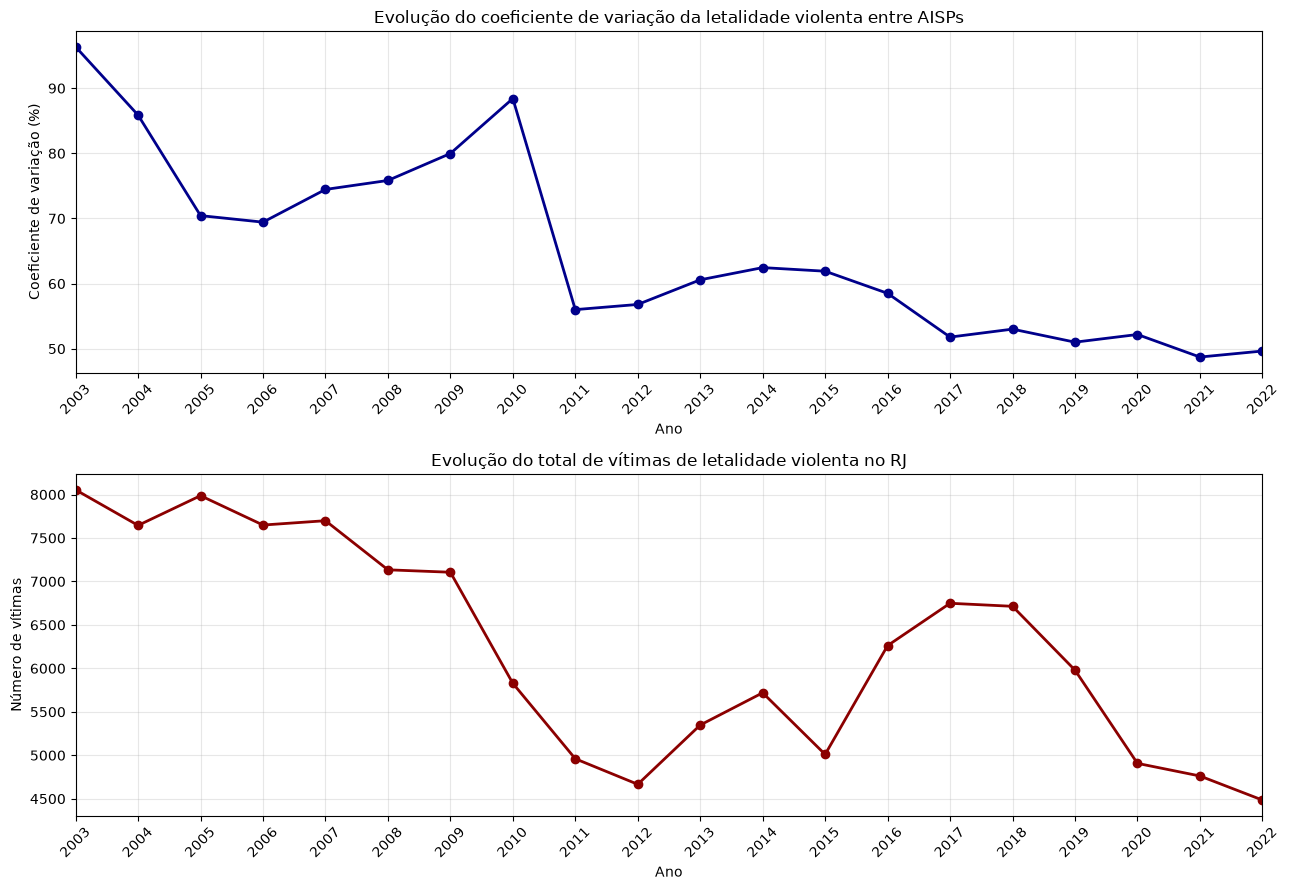

In [20]:
# 1. Coeficiente de variação por ano
cv_anual = resumo_estatistico[
    resumo_estatistico["ano"].between(2003, 2022)
].sort_values("ano")


# 2. Total de letalidades violentas por ano
letalidade_anual = (
    mortes_aisp_ano[
        mortes_aisp_ano["ano"].between(2003, 2022)
    ]
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
    .sort_values("ano")
)


# 3. Criar os gráficos
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

anos = range(2003, 2023)


# Gráfico 1 — Coeficiente de variação
axes[0].plot(
    cv_anual["ano"],
    cv_anual["coef_variacao"],
    marker="o",
    color="darkblue",
    linewidth=2
)

axes[0].set_title(
    "Evolução do coeficiente de variação da letalidade violenta entre AISPs"
)
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Coeficiente de variação (%)")
axes[0].set_xticks(anos)
axes[0].grid(alpha=0.3)


# Gráfico 2 — Total de letalidades violentas
axes[1].plot(
    letalidade_anual["ano"],
    letalidade_anual["quantidade_letalidade_violenta"],
    marker="o",
    color="darkred",
    linewidth=2
)

axes[1].set_title(
    "Evolução do total de vítimas de letalidade violenta no RJ"
)
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Número de vítimas")
axes[1].set_xticks(anos)
axes[1].grid(alpha=0.3)


# Ajustes de apresentação
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlim(2003, 2022)

plt.tight_layout()
plt.show()

Correlação entre o coeficiente de variação e o total de letalidades violentas

In [21]:

# Associar o coeficiente de variação ao total de mortes
correlacao_cv_letalidade = (
    resumo_estatistico[["ano", "coef_variacao"]]
    .merge(letalidade_anual, on="ano")
    .query("2003 <= ano <= 2022")
    .sort_values("ano")
)

correlacao_cv_letalidade

,ano,coef_variacao,quantidade_letalidade_violenta
0,2003,96.351781,8054
1,2004,85.869019,7645
2,2005,70.439578,7987
3,2006,69.437544,7649
4,2007,74.459389,7699
5,2008,75.837798,7134
6,2009,79.976854,7106
7,2010,88.415350,5828
8,2011,56.008576,4960
9,2012,56.802723,4666


Correlação de Pearson: 0.6691


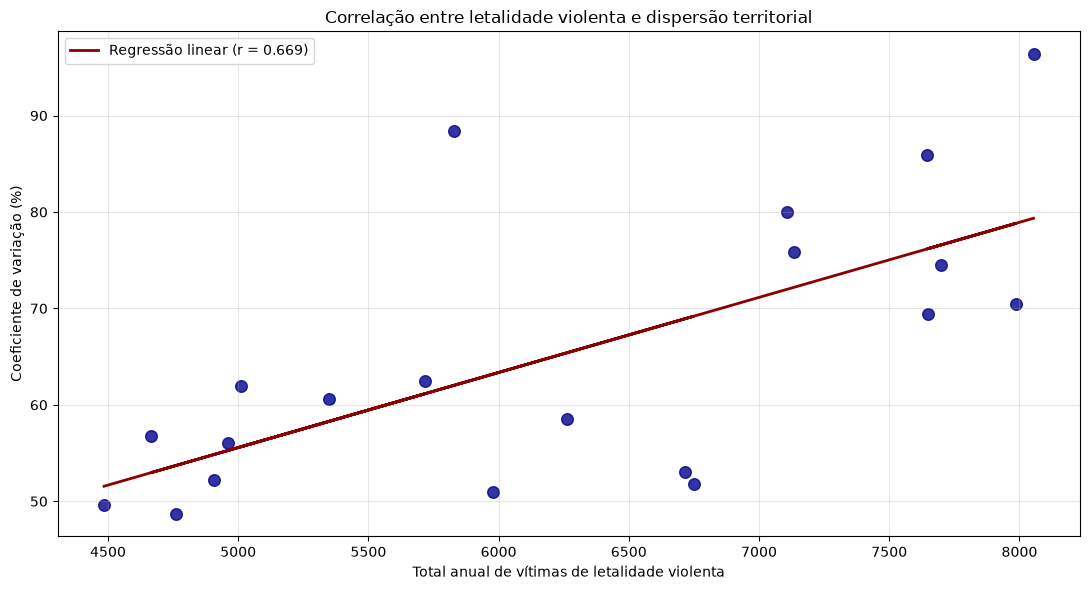

In [22]:
# Calcular correlação de Pearson
r = correlacao_cv_letalidade["coef_variacao"].corr(
    correlacao_cv_letalidade["quantidade_letalidade_violenta"]
)

print(f"Correlação de Pearson: {r:.4f}")

x = correlacao_cv_letalidade["quantidade_letalidade_violenta"]
y = correlacao_cv_letalidade["coef_variacao"]

# Ajuste da reta de regressão
a, b = np.polyfit(x, y, 1)

reta = a * x + b

plt.figure(figsize=(11, 6))

# Pontos
plt.scatter(
    x,
    y,
    color="darkblue",
    s=70,
    alpha=0.8
)

# Reta de regressão
plt.plot(
    x,
    reta,
    color="darkred",
    linewidth=2,
    label=f"Regressão linear (r = {r:.3f})"
)

plt.title(
    "Correlação entre letalidade violenta e dispersão territorial"
)

plt.xlabel("Total anual de vítimas de letalidade violenta")
plt.ylabel("Coeficiente de variação (%)")

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Feminicídios por AISP 

In [23]:
def criar_fig_fem(df_fem_cisp: pd.DataFrame, gdf_aisp: gpd.GeoDataFrame) -> px.choropleth:

    # 1. Agrupar feminicídios por ano e AISP
    df_anual = (
        df_fem_cisp.groupby(["ano", "id_aisp"])
        .agg(
            quantidade_feminicidio = ("quantidade_morte_feminicidio", "sum")
        )
        .reset_index()
    )

    df_anual["nome_aisp"] = "AISP " + df_anual["id_aisp"].astype(str)

    # 2. Preparar dados geográficos
    gdf_aisp = gdf_aisp.copy()

    for col in ["aisp", "AISP", "id_aisp", "ID_AISP"]:
        if col in gdf_aisp.columns:
            gdf_aisp = gdf_aisp.rename(columns={col: "id_aisp"})
            break

    if gdf_aisp.crs is None:
        raise ValueError("O GeoDataFrame não possui CRS definido.")

    if gdf_aisp.crs.to_epsg() != 4326:
        gdf_aisp = gdf_aisp.to_crs(epsg=4326)

    gdf_aisp.geometry = gdf_aisp.geometry.simplify(tolerance=0.005)

    # 3. Padronizar identificadores
    gdf_aisp["id_aisp"] = gdf_aisp["id_aisp"].astype(str)
    df_anual["id_aisp"] = df_anual["id_aisp"].astype(str)

    gdf_aisp = gdf_aisp.set_index("id_aisp")

    # 4. Filtrar período
    df_anim = df_anual[df_anual["ano"].between(2018, 2024)].copy()
    df_anim = df_anim.sort_values(["ano", "id_aisp"])

    # 5. Criar mapa animado
    fig = px.choropleth_map(
        df_anim,
        geojson=gdf_aisp.geometry,
        locations="id_aisp",
        color="quantidade_feminicidio",
        color_continuous_scale="Reds",
        range_color=[0, max(df_anim["quantidade_feminicidio"].max(), 1)],
        animation_frame="ano",
        hover_name="nome_aisp",
        hover_data={
            "id_aisp": False,
            "quantidade_feminicidio": True,
        },
        center={"lat": -22.55, "lon": -43.15},
        zoom=7.4,
        map_style="carto-positron",
        title="<b>Ocorrências de Feminicídio por AISP</b>"
    )

    fig.update_traces(marker_opacity=0.75, marker_line_width=0.5)
    fig.update_layout(height=650, margin=dict(l=20, r=20, t=80, b=20))

    return fig


fig_fem = criar_fig_fem(dados["fem_cisp"], dados["geo_aisp"])
fig_fem.show()

In [24]:
df_fem_cisp 

,ano,mes,id_cisp,id_aisp,id_risp,id_municipio,quantidade_morte_feminicidio,quantidade_tentativa_feminicidio,tipo_fase,data
0,2016,12,1,5,1,3304557,0,0,Consolidado com errata,2016-12-01
1,2016,11,1,5,1,3304557,0,0,Consolidado com errata,2016-11-01
2,2016,12,10,2,1,3304557,0,0,Consolidado com errata,2016-12-01
3,2016,11,10,2,1,3304557,0,0,Consolidado com errata,2016-11-01
4,2016,11,100,37,5,3304110,0,0,Consolidado com errata,2016-11-01
...,...,...,...,...,...,...,...,...,...,...
16719,2026,4,98,10,5,3301801,0,0,Consolidado sem errata,2026-04-01
16720,2026,1,99,37,5,3302254,0,0,Consolidado sem errata,2026-01-01
16721,2026,3,99,37,5,3302254,0,0,Consolidado sem errata,2026-03-01
16722,2026,2,99,37,5,3302254,0,0,Consolidado sem errata,2026-02-01


In [25]:
# Total de feminicídios por ano
feminicidios_ano = (
    df_fem_cisp
    .groupby("ano", as_index=False)["quantidade_morte_feminicidio"]
    .sum()
)

# Total de letalidades violentas por ano
letalidades_ano = (
    mortes_aisp_ano
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
)
correlacao_feminicidio = (
    feminicidios_ano
    .merge(letalidades_ano, on="ano", validate="one_to_one")
    .query("2016 <= ano <= 2025")
    .sort_values("ano")
)

correlacao_feminicidio



,ano,quantidade_morte_feminicidio,quantidade_letalidade_violenta
0,2016,14,6262
1,2017,68,6749
2,2018,71,6714
3,2019,85,5980
4,2020,78,4907
5,2021,85,4762
6,2022,111,4485
7,2023,99,4270
8,2024,107,3809
9,2025,105,3892


Correlação de Pearson: -0.7189


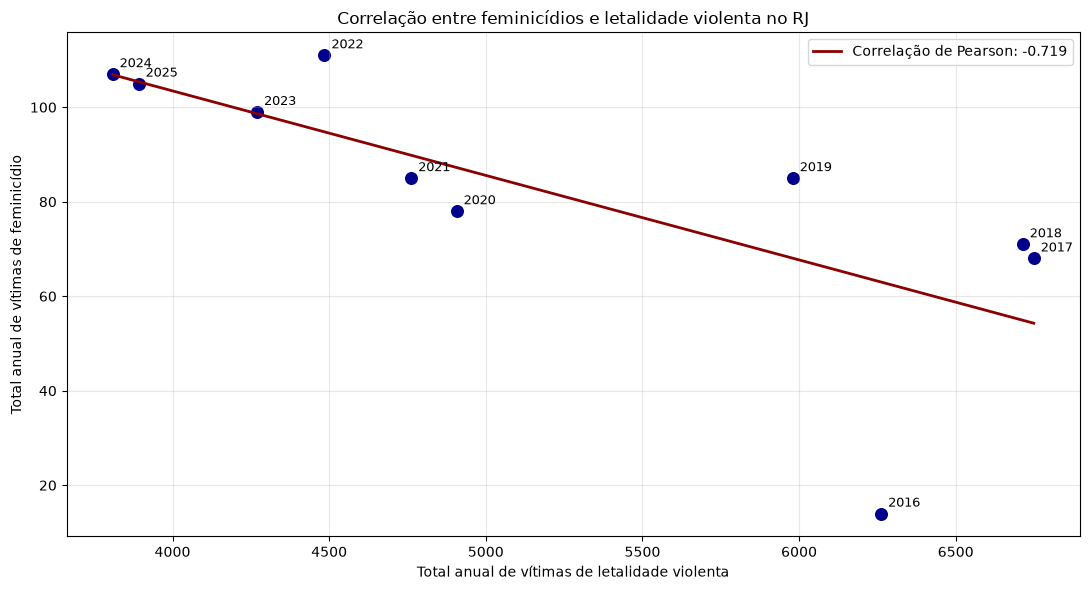

In [26]:
r = correlacao_feminicidio[
    "quantidade_morte_feminicidio"
].corr(
    correlacao_feminicidio["quantidade_letalidade_violenta"]
)

print(f"Correlação de Pearson: {r:.4f}")


import matplotlib.pyplot as plt
import numpy as np

x = correlacao_feminicidio["quantidade_letalidade_violenta"]
y = correlacao_feminicidio["quantidade_morte_feminicidio"]

# Regressão linear
a, b = np.polyfit(x, y, 1)

plt.figure(figsize=(11, 6))

# Pontos
plt.scatter(
    x,
    y,
    color="darkblue",
    s=70
)

# Reta de regressão
plt.plot(
    np.sort(x),
    a * np.sort(x) + b,
    color="darkred",
    linewidth=2,
    label=f"Correlação de Pearson: {r:.3f}"
)

# Identificar os anos
for _, linha in correlacao_feminicidio.iterrows():
    plt.annotate(
        str(int(linha["ano"])),
        (
            linha["quantidade_letalidade_violenta"],
            linha["quantidade_morte_feminicidio"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Correlação entre feminicídios e letalidade violenta no RJ")
plt.xlabel("Total anual de vítimas de letalidade violenta")
plt.ylabel("Total anual de vítimas de feminicídio")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## A variação da letalidade violenta das 3 regioes que aparecem no top 10

## Pergunta 3

In [27]:
df_regiao = df_cisp_mensal.groupby(['mes', 'id_risp'])['quantidade_letalidade_violenta'].mean().reset_index()
df_geral = df_cisp_mensal.groupby(['mes'])['quantidade_letalidade_violenta'].mean().reset_index()



nomes_regioes = {
    1: 'Capital - Zona Sul',
    2: 'Capital - Zona Oeste',
    3: 'Baixada Fluminense',
    4: 'Grande Niterói',
    5: 'Sul Fluminense',
    6: 'Norte Fluminense',
    7: 'Região Serrana'
}

df_geral_plot = df_geral.copy()
df_geral_plot['id_risp'] = 'Média Geral'
df_plotly = pd.concat([df_regiao, df_geral_plot], ignore_index=True)
df_plotly['id_risp'] = df_plotly['id_risp'].replace(nomes_regioes)

meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig = px.line(
    df_plotly, 
    x='mes', 
    y='quantidade_letalidade_violenta', 
    color='id_risp',
    markers=False,
    title='Média mensal de crimes por letalidade violenta',
    labels={'id_risp': ''}
)

# Alocação dos meses no eixo x
fig.update_layout(
    xaxis=dict(tickmode='array', tickvals=list(range(1, 13)), ticktext=meses),
    title_x=0.45,
    title_y=0.86,
    title_font_size=24,
    xaxis_title='',
    yaxis_title='',
    legend=dict(
        font=dict(size=14)
    )
)


fig.update_traces(
    line=dict(width=3, color='black'),
    opacity=0.6,
    selector=dict(name='Média Geral')
)

fig.show()

## Pergunta 5

In [28]:
COLUNAS_CLUSTER = ["taxa_fuzil_100k", "taxa_intervencao_100k"]
K_CLUSTERS = 3
NOMES_NIVEIS = {3: ["Baixa intensidade", "Intensidade intermediária", "Alta intensidade (fuzis e intervenção)"]}
nomes_niveis = NOMES_NIVEIS.get(K_CLUSTERS, [f"Nível {i + 1}" for i in range(K_CLUSTERS)])
cores_niveis = [PALETA["azul"], PALETA["amarelo"], PALETA["vermelho"]]
if K_CLUSTERS != 3:
    cores_niveis = list(plt.cm.viridis(np.linspace(0, 1, K_CLUSTERS)))

# 1. Ano de análise: o mais recente com todas as variáveis disponíveis
candidatos = painel_aisp.dropna(subset=[*COLUNAS_CLUSTER, "populacao"])
ano_analise = int(candidatos["ano"].max())
df_ano = candidatos[candidatos["ano"] == ano_analise].copy()
n_painel_ano = int((painel_aisp["ano"] == ano_analise).sum())
print(
    f"Ano de análise: {ano_analise} (último com população). "
    f"AISPs no K-Means: {len(df_ano)}; fora por falta de dados: {n_painel_ano - len(df_ano)}."
)

# 2. Transformação e padronização
X_log = np.log1p(df_ano[COLUNAS_CLUSTER].to_numpy())
X_scaled = StandardScaler().fit_transform(X_log)

# 3. Escolha de k: silhouette e inércia para k = 2..6
diagnostico_k = []
for k in range(2, min(7, len(df_ano))):
    modelo_k = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10).fit(X_scaled)
    diagnostico_k.append(
        {"k": k, "silhouette": silhouette_score(X_scaled, modelo_k.labels_), "inercia": modelo_k.inertia_}
    )
diagnostico_k = pd.DataFrame(diagnostico_k).round(3)
display(diagnostico_k)
melhor_k = int(diagnostico_k.loc[diagnostico_k["silhouette"].idxmax(), "k"])
print(f"Melhor silhouette: k = {melhor_k}. k usado na análise: {K_CLUSTERS} (definido pelos três níveis de intensidade).")

# 4. Modelo final e ordenação dos grupos pelo centroide (média dos dois eixos padronizados)
kmeans = KMeans(n_clusters=K_CLUSTERS, random_state=SEMENTE, n_init=10).fit(X_scaled)
ordem_grupos = np.argsort(kmeans.cluster_centers_.sum(axis=1))
nivel_do_grupo = {grupo: nivel for nivel, grupo in enumerate(ordem_grupos)}
df_ano["nivel"] = pd.Series(kmeans.labels_, index=df_ano.index).map(nivel_do_grupo)
df_ano["Classificação K-Means"] = df_ano["nivel"].map(dict(enumerate(nomes_niveis)))
df_ano["cor_cluster"] = df_ano["nivel"].map(dict(enumerate(cores_niveis)))
mapa_cores_nome = dict(zip(nomes_niveis, cores_niveis))

# 5. Estabilidade da partição frente à inicialização (ARI = 1 → partições idênticas)
aris = [
    adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=K_CLUSTERS, random_state=s, n_init=1).fit_predict(X_scaled))
    for s in range(20)
]
print(f"Estabilidade (ARI contra o modelo final, 20 sementes): média = {np.mean(aris):.2f}, mínimo = {np.min(aris):.2f}")

# 6. Associação entre as duas taxas: no ano de análise e em cada ano da série
rho_ano, p_ano = stats.spearmanr(df_ano[COLUNAS_CLUSTER[0]], df_ano[COLUNAS_CLUSTER[1]])
print(f"Spearman entre fuzis e intervenção policial (por 100 mil), {ano_analise}: ρ = {rho_ano:.2f}, p = {p_ano:.4f} (n = {len(df_ano)})")

rho_por_ano = []
for ano, grupo in painel_aisp.dropna(subset=COLUNAS_CLUSTER).groupby("ano"):
    if len(grupo) >= 8:
        rho_a, p_a = stats.spearmanr(grupo[COLUNAS_CLUSTER[0]], grupo[COLUNAS_CLUSTER[1]])
        rho_por_ano.append({"ano": int(ano), "n_aisp": len(grupo), "rho_spearman": rho_a, "p_valor": p_a})
rho_por_ano = pd.DataFrame(rho_por_ano, columns=["ano", "n_aisp", "rho_spearman", "p_valor"])

print("\nAISPs por grupo:")
print(df_ano["Classificação K-Means"].value_counts().reindex(nomes_niveis).to_string())

# 7. Junção espacial (inner: só AISPs com dados e polígono; a perda é informada)
gdf_aisp_map = gdf_aisp.merge(df_ano, on="id_aisp", how="inner", validate="one_to_one")
if gdf_aisp_map.empty:
    raise ValueError(f"O cruzamento resultou em 0 linhas para o ano {ano_analise}. Verifique as chaves territoriais.")
print(f"\nAISPs com dados mas sem polígono (não aparecem nos mapas): {len(df_ano) - len(gdf_aisp_map)}.")


NameError: name 'PALETA' is not defined

In [29]:
gdf_idx = gdf_aisp_map.set_index("id_aisp")
dados_plot = gdf_idx.drop(columns="geometry")

fig_scatter = px.scatter(
    dados_plot.reset_index(),
    x=COLUNAS_CLUSTER[0],
    y=COLUNAS_CLUSTER[1],
    color="Classificação K-Means",
    color_discrete_map=mapa_cores_nome,
    category_orders={"Classificação K-Means": nomes_niveis},
    hover_name="rotulo_aisp",
    hover_data={
        COLUNAS_CLUSTER[0]: ":.2f", COLUNAS_CLUSTER[1]: ":.2f",
        "quantidade_fuzil": True, "Classificação K-Means": False,
    },
    title=f"Grupos de AISPs (K-Means) – {ano_analise}",
    labels={
        COLUNAS_CLUSTER[0]: "Fuzis apreendidos por 100 mil hab.",
        COLUNAS_CLUSTER[1]: "Mortes por intervenção policial por 100 mil hab.",
    },
)
fig_scatter.add_vline(x=df_ano[COLUNAS_CLUSTER[0]].median(), line_width=1, line_dash="dash", line_color="gray")
fig_scatter.add_hline(y=df_ano[COLUNAS_CLUSTER[1]].median(), line_width=1, line_dash="dash", line_color="gray")
fig_scatter.update_traces(marker=dict(size=12, line=dict(width=1, color="DarkSlateGrey")))
fig_scatter.update_layout(template="plotly_white", height=500)
fig_scatter.show()

fig_map = px.choropleth_map(
    dados_plot,
    geojson=gdf_idx.geometry,
    locations=dados_plot.index,
    color="Classificação K-Means",
    color_discrete_map=mapa_cores_nome,
    category_orders={"Classificação K-Means": nomes_niveis},
    hover_name="rotulo_aisp",
    hover_data={
        COLUNAS_CLUSTER[0]: ":.2f", COLUNAS_CLUSTER[1]: ":.2f",
        "quantidade_fuzil": True, "Classificação K-Means": False,
    },
    center={"lat": -22.55, "lon": -43.15},
    zoom=7.2,
    map_style="carto-positron",
    title=f"Distribuição territorial dos grupos (K-Means) – {ano_analise}",
)
fig_map.update_traces(marker_opacity=0.8, marker_line_width=0.5)
fig_map.update_layout(height=600, margin=dict(l=20, r=20, t=60, b=20))
fig_map.show()


NameError: name 'gdf_aisp_map' is not defined